# Paso a paso de como hacer un plot de cada extension y crear un histograma de la region de interes, ajustando una curva y obtener los paramtros del ajuste.

### Importar librerias para abrir imagfenes .FITS y para plotear imagenes

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from astropy.io import fits

In [3]:
plt.rcParams.update({
    "image.origin": "lower",
    "image.aspect": 1,
    #"text.usetex": True,
    "grid.alpha": .5,
    "axes.linewidth":2,
    "lines.linewidth" : 1,
    "font.size":    12.0,
    "xaxis.labellocation": 'right',  # alignment of the xaxis label: {left, right, center}
    "yaxis.labellocation": 'top',  # alignment of the yaxis label: {bottom, top, center}
    "xtick.top":           True ,  # draw ticks on the top side
    "xtick.major.size":    8    ,# major tick size in points
    "xtick.minor.size":    4      ,# minor tick size in points
    "xtick.direction":     'in',
    "xtick.minor.visible": True,
    "ytick.right":           True ,  # draw ticks on the top side
    "ytick.major.size":    8    ,# major tick size in points
    "ytick.minor.size":    4      ,# minor tick size in points
    "ytick.direction":     'in',
    "ytick.minor.visible": True,
    "ytick.major.width":   2   , # major tick width in points
    "ytick.minor.width":   1 ,
    "xtick.major.width":   2   , # major tick width in points
    "xtick.minor.width":   1 ,
    "legend.framealpha": 0 ,
    "legend.loc": 'best',

})

In [4]:
path='/home/oem/datosFits/Data_2023/spuriousCharge/Microchip/14AUG23/proc_skp_module24_MITLL01_externalVr-4_Vv2_T140__NSAMP225_NROW650_NCOL700_EXPOSURE0_NBINROW1_NBINCOL1_img109.fits'

In [5]:
path='/home/oem/datosFits/Data_2023/01NOV2023/proc_skp_m-009_microchip_T_170__Vv82_NSAMP_324_NROW_400_NCOL_700_EXPOSURE_0_NBINROW_1_NBINCOL_1_img_82.fits'

### Crear una lista con los datos por cada extension

In [6]:
imagen=fits.open(path)
data_Ext=[]
for i in range(0,4):
    data_Ext.append(imagen[i].data)
    

Min=data_Ext[0].min()
Max=data_Ext[0].max()

### Podemos hacer plot de cada extension

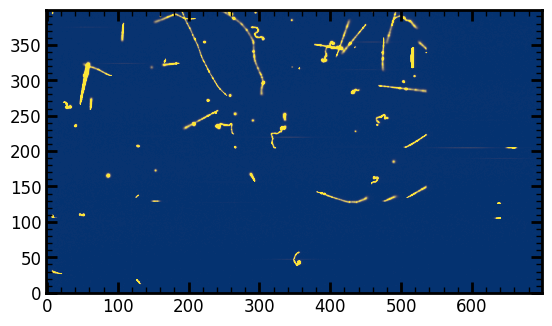

In [7]:
plt.imshow(data_Ext[0], vmin=0, vmax=Max*.05, cmap='cividis', origin='lower')

### Hacer plot de una region en particular, sobre la que queramos conocer su distribucion de pixeles

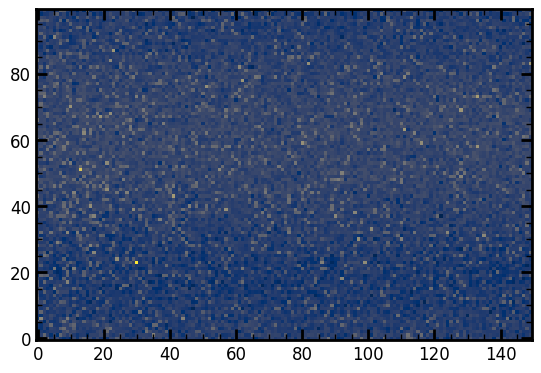

In [8]:
plt.imshow(data_Ext[0][300:400,550:], cmap='cividis', origin='lower')

In [9]:
NROW=int(imagen[0].header['NROW'])
NCOL=int(imagen[0].header['NCOL'])

irow=117
icolOS_low=550
icolOS_hi=NCOL
np.median(imagen[0].data[irow-1,icolOS_low:icolOS_hi])

irow=117     # Y
icol=302     # X
Qij=imagen[0].data[irow-1,icol-1]
print(Qij)
Qos=Qij-np.median(imagen[0].data[irow-1,icolOS_low:icolOS_hi])
print(Qos)

14422.447
-17.097656


In [10]:
new_image=np.zeros(shape=(NROW,NCOL))
for row in range(0,NROW,1):
    for col in range(0,icolOS_low, 1):
        new_image[row][col]=imagen[0].data[row][col]-np.median(imagen[0].data[row,icolOS_low:icolOS_hi])
    for col in range(icolOS_low, NCOL, 1):
        new_image[row][col]=imagen[0].data[row][col]-np.median(imagen[0].data[row,icolOS_low:icolOS_hi])

carga cruda Qij=14422.447
carga media sustraida=-17.09765625


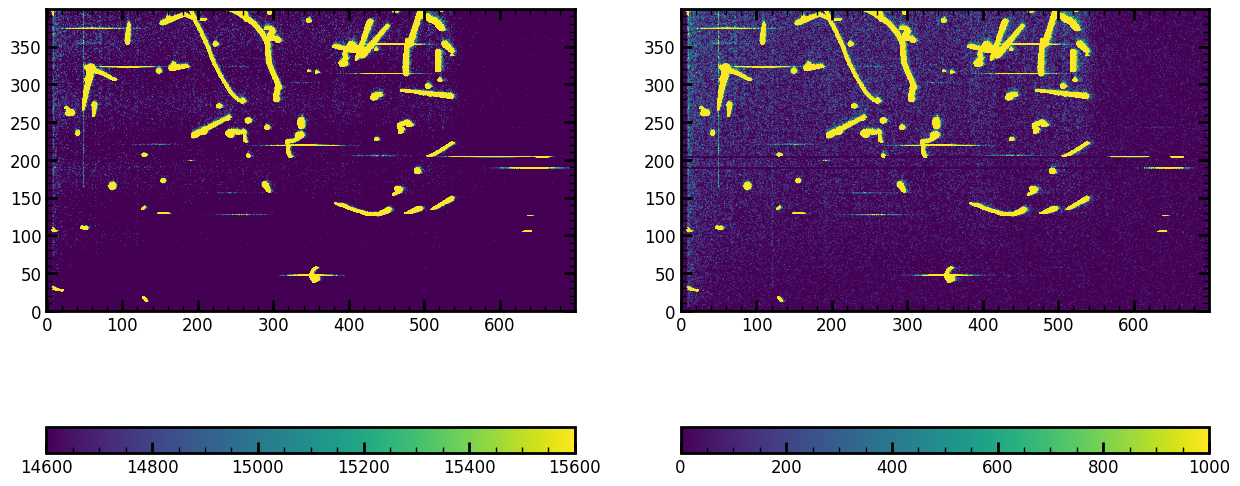

In [11]:
fig, (raw, median_sus)=plt.subplots(ncols=2, figsize=(15,10))
cruda=raw.imshow(imagen[0].data, vmin=14600, vmax=15600)
ok=median_sus.imshow(new_image, vmin=0, vmax=1000)

fig.colorbar(cruda, ax=raw, orientation='horizontal')
fig.colorbar(ok, ax=median_sus, orientation='horizontal')



irow=117     # Y
icol=302     # X
Qij_medianSus=new_image[irow-1,icol-1]
print("carga cruda Qij="+str(Qij))
print("carga media sustraida="+str(Qij_medianSus))

### histogram devuelve las componentes X (bines) y Y (cuentas de cada bin) de un histograma

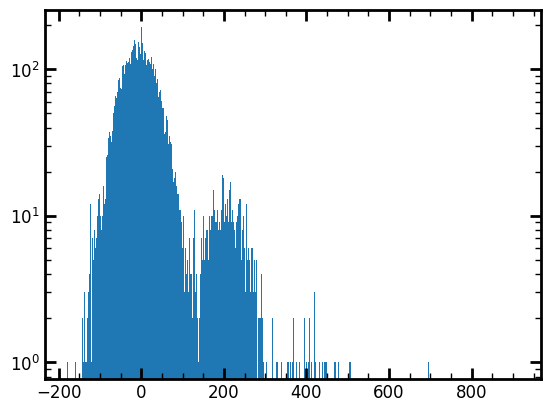

In [12]:
#counts_Y, bins_X, _ = plt.hist(data_Ext[0][300:400,550:].flatten(),1000)
counts_Y, bins_X, _ = plt.hist(new_image[300:400,550:].flatten(),1000)
plt.yscale('log')

## maneras diferentes de hacer un plot de las 4 extensiones

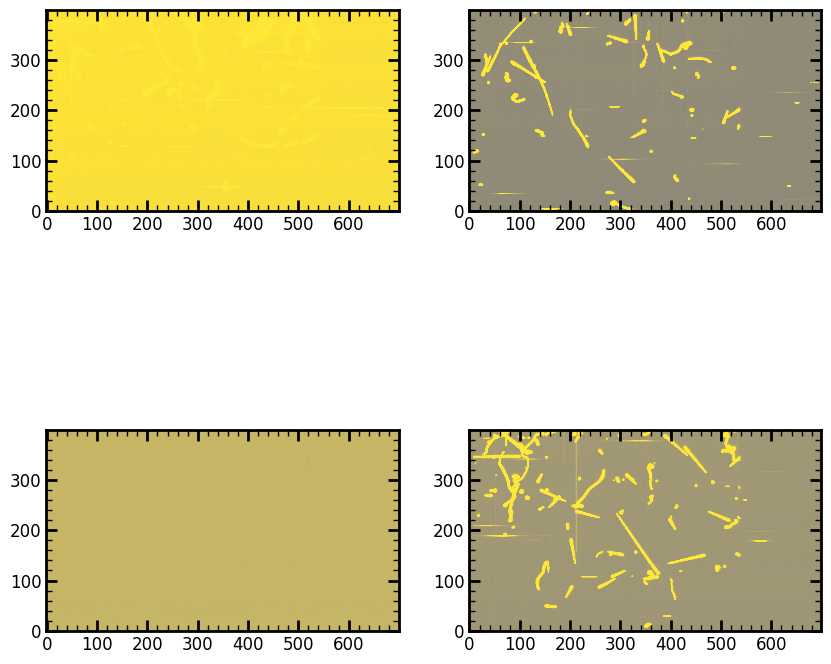

In [13]:
fig=plt.figure(figsize=(10,10))  #definimos Tamaño de la Figura

#Colocar en el canvas las 4 extensiones
plt.subplot(2,2,1)
plt.imshow(data_Ext[0], vmin=0, vmax=Max*.005, cmap='cividis', origin='lower')

plt.subplot(2,2,2)
plt.imshow(data_Ext[1], vmin=0, vmax=Max*.005, cmap='cividis', origin='lower')

plt.subplot(2,2,3)
plt.imshow(data_Ext[2], vmin=0, vmax=Max*.005, cmap='cividis', origin='lower')

plt.subplot(2,2,4)
plt.imshow(data_Ext[3], vmin=0, vmax=Max*.005, cmap='cividis', origin='lower')

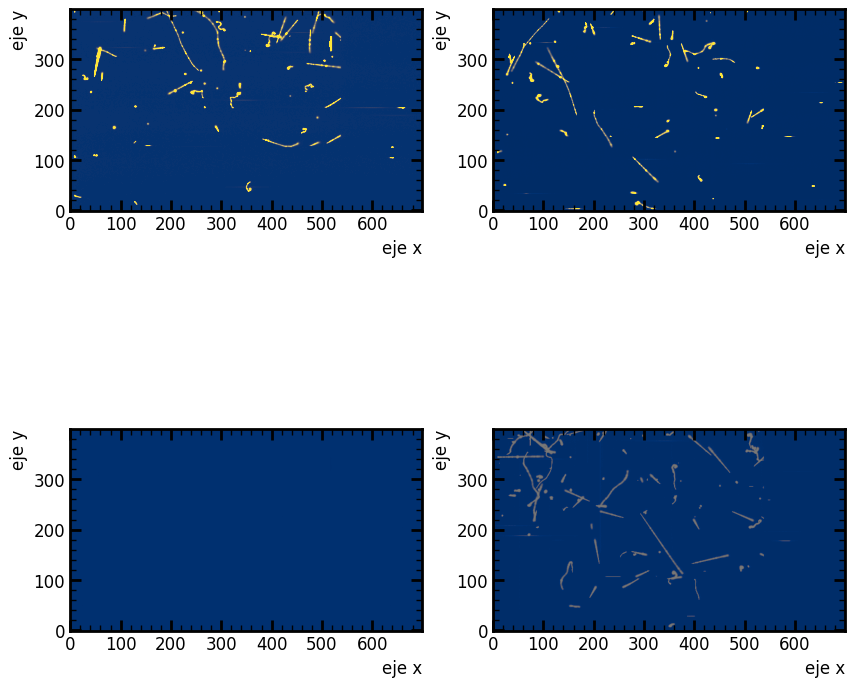

In [14]:
fig=plt.figure(figsize=(10,10))  #definimos Tamaño de la Figura
for i in range(0,4):
    #Colocar en el canvas las 4 extensiones
    plt.subplot(2,2,i+1)
    plt.imshow(data_Ext[i], vmin=0, vmax=Max*.05, cmap='cividis', origin='lower')
    plt.xlabel('eje x')
    plt.ylabel('eje y')
    

### Tarea Hacer el plot manejando las variables como objetos


In [15]:
# from numpy import linspace as linspace
# x = linspace(0, 2, 100)  # Sample data.

# # Note that even in the OO-style, we use `.pyplot.figure` to create the figure.
# fig, ax = plt.subplots(2,2)  # Create a figure and an axes.
# ax[0].plot(x, x, label='linear')  # Plot some data on the axes.
# ax[0].plot(x, x**2, label='quadratic')  # Plot more data on the axes...
# ax[0].plot(x, x**3, label='cubic')  # ... and some more.
# ax[0].set_xlabel('x label')  # Add an x-label to the axes.
# ax[0].set_ylabel('y label')  # Add a y-label to the axes.
# ax[0].set_title("Simple Plot")  # Add a title to the axes.
# ax[0].legend()  # Add a legend.

# Ajuste de una curva en nuestro histograma
El proposito es conocer los parametros de la curva a partir de los datos experimentales. Para ello nos apollaremos en la funcion curve_fit

In [16]:
from scipy.optimize import curve_fit
import numpy as np

## Definir la curva a ajustar

In [17]:

def gauss(x,x0,s,A): # x=data, x0=mean, s=StdDev, A=amplitud
    return A*np.exp(-(x-x0)**2/(2*s**2))/np.sqrt(np.pi*2*s**2)

### Es necesario ajustar la cantidad de bins
### popt contiene los valores optimos para el ajuste de la curva
### popt contiene x0=mean, s=StdDev, A=amplitud

In [18]:
bins= (bins_X[1:]+bins_X[:-1])/2
popt,pcov=curve_fit(gauss, bins,counts_Y, p0=(0,40, 130))

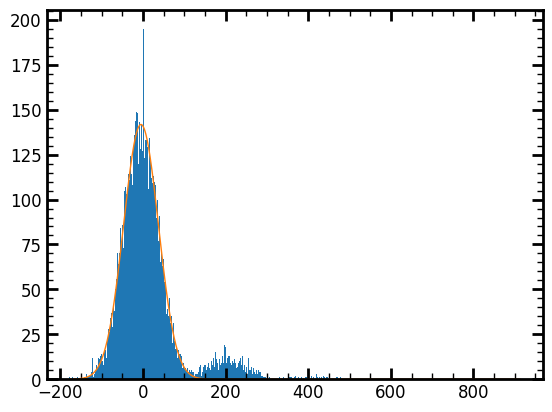

In [19]:
y,x,_=plt.hist(new_image[300:400,550:].flatten(),1000)
plt.plot(bins, gauss(bins, *popt))


## Ajustar una Gausiana doble
### Definir la funcion y establecer los parametros necesarios

In [20]:
def gaussian2(x,m,s,g,a1,a2): #data, mean, sigma, gain, height1, heigth2
    return a1*np.exp(-1/2*((x-m)/s)**2)+a2*np.exp(-1/2*((x-m-g)/s)**2)

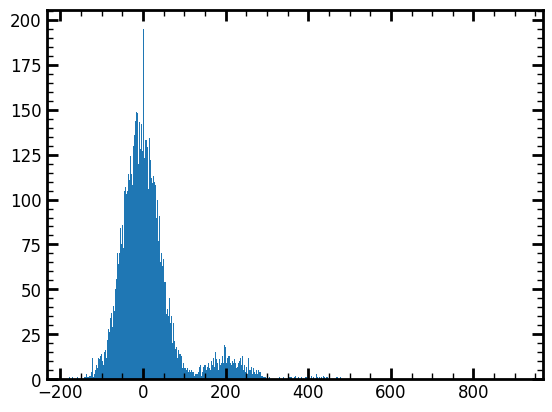

In [21]:
counts_Y, bins_X, _ = plt.hist(new_image[300:400,550:].flatten(),1000)
#plt.yscale('log')

In [22]:
bins= (bins_X[1:]+bins_X[:-1])/2                                    #p0= Parametros iniciales
popt,pcov=curve_fit(gaussian2, bins,counts_Y,p0=(0,40,205,90,10))   #una primera aproximacion de los valores optimos
                                                                    #del ajunte

mean=-5.054060508978548 
sigma:42.04849210896861 
gain: 208.10154575365434 
 h1: 141.89857744024084
 h2: 12.312092057395272



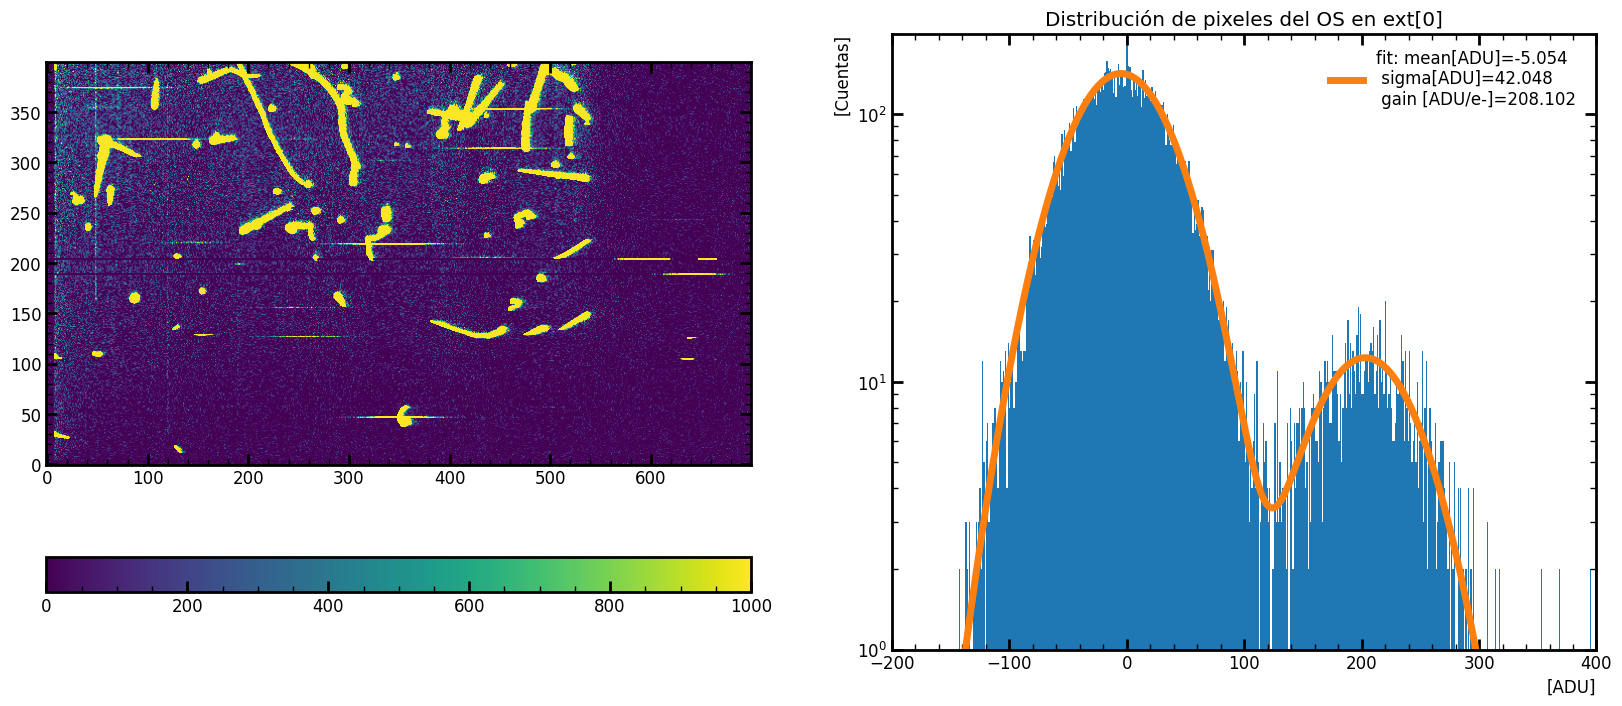

In [23]:
fig, (imagen, distribucion)=plt.subplots(ncols=2, figsize=(20,8))

ok=imagen.imshow(new_image, vmin=0, vmax=1000)

distribucion=y,x,_=plt.hist(new_image[300:400,550:].flatten(),1000)
plt.plot(bins, gaussian2(bins, *popt),label='fit: mean[ADU]=%5.3f \n sigma[ADU]=%5.3f \n gain [ADU/e-]=%5.3f ' % (popt[0],popt[1],popt[2]),linewidth=5)
print("mean={} \nsigma:{} \ngain: {} \n h1: {}\n h2: {}\n".format(*popt))
plt.ylim(1,200)
plt.xlim(-200,400)
plt.xlabel('[ADU]')
plt.ylabel('[Cuentas]')
plt.title('Distribución de pixeles del OS en ext[0]')
plt.legend()
plt.yscale('log')
Ganancia=popt[2]
fig.colorbar(ok, ax=imagen, orientation='horizontal')

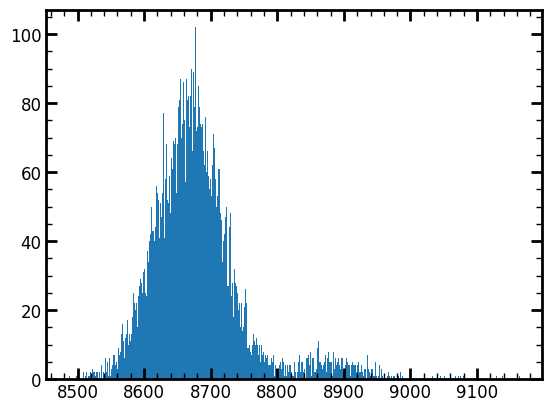

In [24]:
counts_Y, bins_X, _ = plt.hist(data_Ext[1][300:400,550:].flatten(),1000)
bins= (bins_X[1:]+bins_X[:-1])/2                                    #p0= Parametros iniciales
popt,pcov=curve_fit(gaussian2, bins,counts_Y,p0=(8680,40,205,90,10))   #una primera aproximacion de los valores optimos


mean=8667.720719181549 
sigma:48.89097465955267 
gain: 206.60861947746824 
 h1: 77.82978920552569
 h2: 4.90053184263278



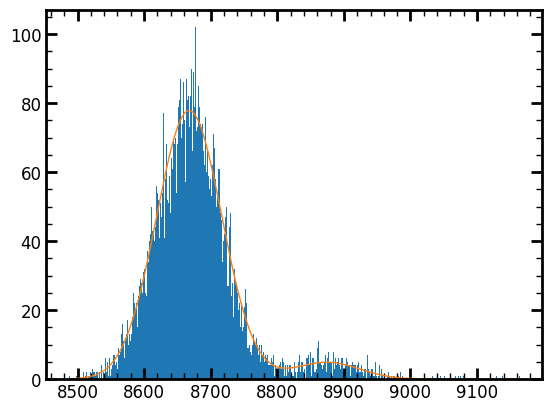

In [25]:
y,x,_=plt.hist(data_Ext[1][300:400,550:].flatten(),1000)
plt.plot(bins, gaussian2(bins, *popt))
print("mean={} \nsigma:{} \ngain: {} \n h1: {}\n h2: {}\n".format(*popt))

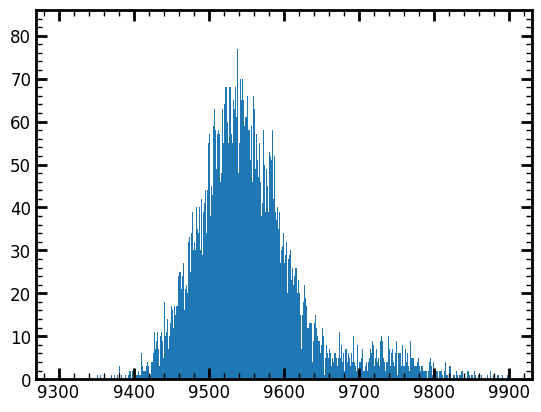

In [26]:
counts_Y, bins_X, _ = plt.hist(data_Ext[3][300:400,550:].flatten(),1000, range=(9300,9900))
bins= (bins_X[1:]+bins_X[:-1])/2                                    #p0= Parametros iniciales
popt,pcov=curve_fit(gaussian2, bins,counts_Y,p0=(9550,40,205,90,10))   #una primera aproximacion de los valores optimos

mean=9540.793360495754 
sigma:52.47235475522556 
gain: 189.64038022482723 
 h1: 62.373213041014516
 h2: 5.486038885265646



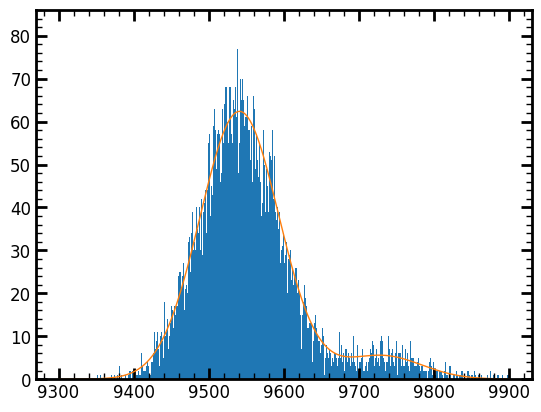

In [27]:
y,x,_=plt.hist(data_Ext[3][300:400,550:].flatten(),1000, range=(9300,9900))
plt.plot(bins, gaussian2(bins, *popt))
print("mean={} \nsigma:{} \ngain: {} \n h1: {}\n h2: {}\n".format(*popt))

In [28]:

path_nsamp1='/home/oem/datosFits/Data_2023/06OCT23/nsamp/proc_skp_m-009_microchip_vtested_T_170__seq__NSAMP_1_NROW_650_NCOL_700_EXPOSURE_0_NBINROW_1_NBINCOL_1_img_1237.fits'
imagen_nsamp1=fits.open(path_nsamp1)
data_nsamp1=[]
for i in range(0,4):
    data_nsamp1.append(imagen_nsamp1[i].data)
    

Min_nsamp1=data_nsamp1[0].min()
Max_nsamp1=data_nsamp1[0].max()

NROW_nsamp1=int(imagen_nsamp1[0].header['NROW'])
NCOL_nsamp1=int(imagen_nsamp1[0].header['NCOL'])

irow_nsamp1=117
icolOS_low_nsamp1=550
icolOS_hi_nsamp1=NCOL_nsamp1
np.median(imagen_nsamp1[0].data[irow_nsamp1-1,icolOS_low_nsamp1:icolOS_hi_nsamp1])


icol_nsamp1=302     # X
Qij=imagen_nsamp1[0].data[irow_nsamp1-1,icol_nsamp1-1]
print(Qij)
Qos=Qij-np.median(imagen_nsamp1[0].data[irow_nsamp1-1,icolOS_low_nsamp1:icolOS_hi_nsamp1])
print(Qos)

new_image_nsamp1=np.zeros(shape=(NROW_nsamp1,NCOL_nsamp1))
for row in range(0,NROW_nsamp1,1):
    for col in range(0,icolOS_low_nsamp1, 1):
        new_image_nsamp1[row][col]=imagen_nsamp1[0].data[row][col]-np.median(imagen_nsamp1[0].data[row,icolOS_low_nsamp1:icolOS_hi_nsamp1])
    for col in range(icolOS_low_nsamp1, NCOL_nsamp1, 1):
        new_image_nsamp1[row][col]=imagen_nsamp1[0].data[row][col]-np.median(imagen_nsamp1[0].data[row,icolOS_low_nsamp1:icolOS_hi_nsamp1])




7475.0
61.0


In [29]:
path_nsamp324='/home/oem/datosFits/Data_2023/06OCT23/nsamp/proc_skp_m-009_microchip_vtested_T_170__seq__NSAMP_324_NROW_650_NCOL_700_EXPOSURE_0_NBINROW_1_NBINCOL_1_img_1246.fits'
imagen_nsamp324=fits.open(path_nsamp324)
data_nsamp324=[]
for i in range(0,4):
    data_nsamp324.append(imagen_nsamp324[i].data)
    

Min_nsamp324=data_nsamp324[0].min()
Max_nsamp324=data_nsamp324[0].max()

NROW_nsamp324=int(imagen_nsamp324[0].header['NROW'])
NCOL_nsamp324=int(imagen_nsamp324[0].header['NCOL'])

irow_nsamp324=117
icolOS_low_nsamp324=550
icolOS_hi_nsamp324=NCOL_nsamp324
np.median(imagen_nsamp324[0].data[irow_nsamp324-1,icolOS_low_nsamp324:icolOS_hi_nsamp324])


icol_nsamp324=302     # X
Qij=imagen_nsamp324[0].data[irow_nsamp324-1,icol_nsamp324-1]
print(Qij)
Qos=Qij-np.median(imagen_nsamp324[0].data[irow_nsamp324-1,icolOS_low_nsamp324:icolOS_hi_nsamp324])
print(Qos)

new_image_nsamp324=np.zeros(shape=(NROW_nsamp324,NCOL_nsamp324))
for row in range(0,NROW_nsamp324,1):
    for col in range(0,icolOS_low_nsamp324, 1):
        new_image_nsamp324[row][col]=imagen_nsamp324[0].data[row][col]-np.median(imagen_nsamp324[0].data[row,icolOS_low_nsamp324:icolOS_hi_nsamp324])
    for col in range(icolOS_low_nsamp324, NCOL_nsamp324, 1):
        new_image_nsamp324[row][col]=imagen_nsamp324[0].data[row][col]-np.median(imagen_nsamp324[0].data[row,icolOS_low_nsamp324:icolOS_hi_nsamp324])


14402.253
26.490234


[(-150.0, 350.0),
 (1.0, 200.0),
 None,
 Text(1, 0, '[ADU]'),
 Text(0, 1, '[Cuentas]'),
 Text(0.5, 1.0, 'Distribución de pixeles del OS nsamp=324')]

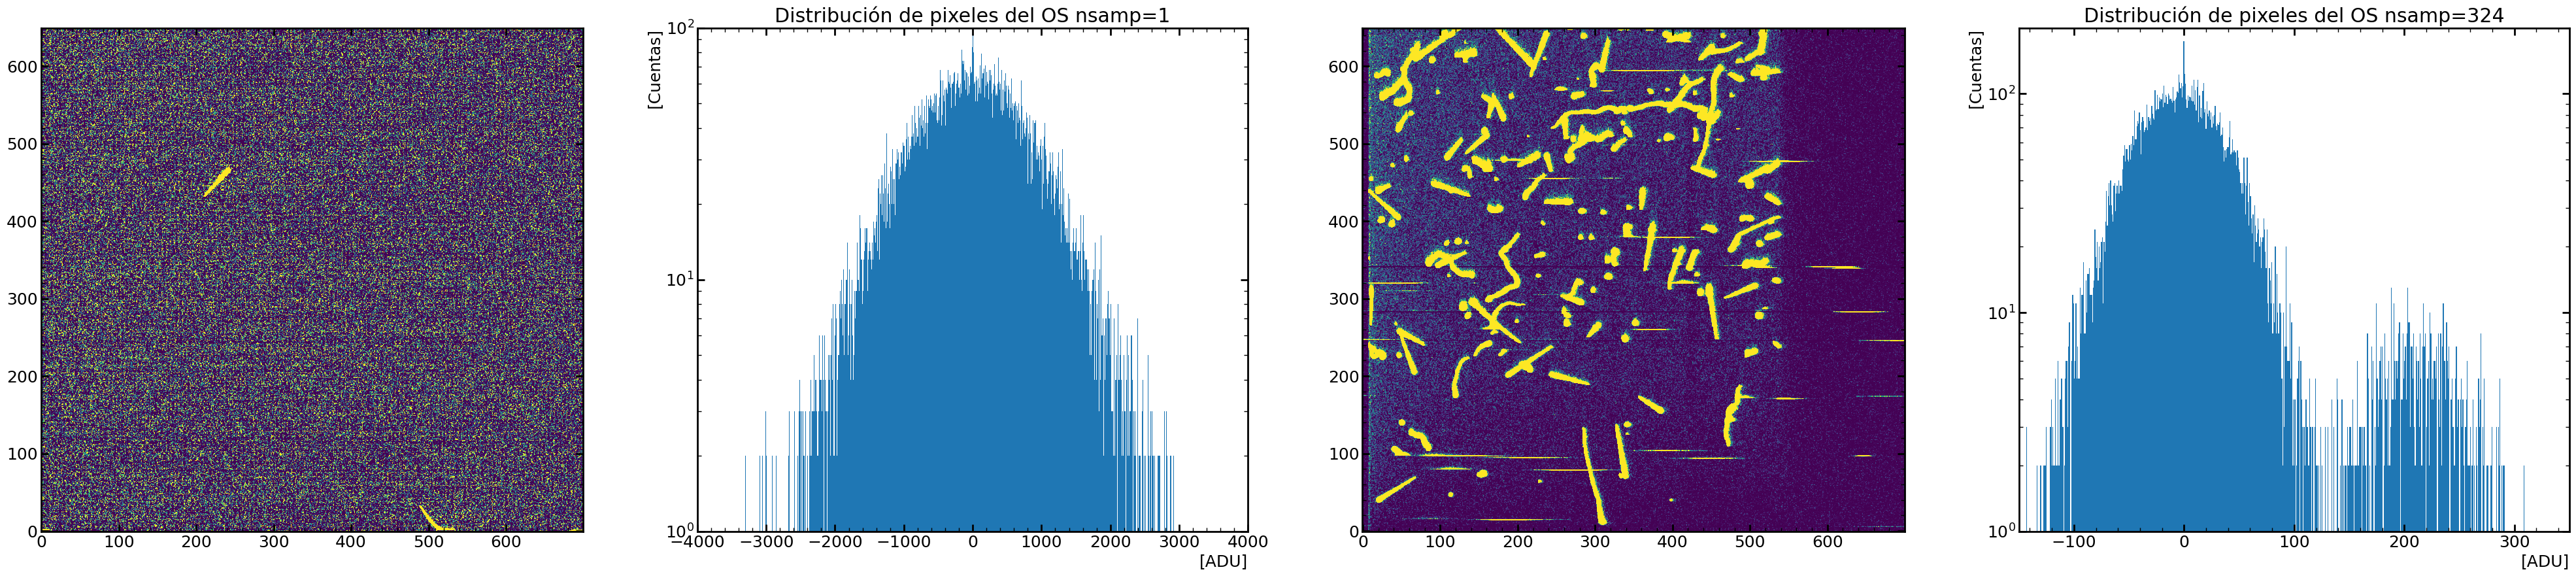

In [30]:
plt.rcParams.update({"font.size":    18.0})
fig, (imagen_nsamp1, distribucion_nsamp1, imagen_nsamp324, distribucion_nsamp324)=plt.subplots(ncols=4, figsize=(50,10))
#imagen nsamp 1
imagen_nsamp1.imshow(new_image_nsamp1, vmin=0, vmax=1000)
#distribucion nsamp 1
distribucion_nsamp1.hist(new_image_nsamp1[300:400,550:].flatten(),1000)
distribucion_nsamp1.set(xlim=(-4000,4000), ylim=(1,100), yscale='log', xlabel='[ADU]', ylabel='[Cuentas]', title='Distribución de pixeles del OS nsamp=1')


#imagen nsamp 324
imagen_nsamp324.imshow(new_image_nsamp324, vmin=0, vmax=1000)
#distribucion nsamp 324
distribucion_nsamp324.hist(new_image_nsamp324[500:600,550:].flatten(),1000)
distribucion_nsamp324.set(xlim=(-150,350), ylim=(1,200), yscale='log', xlabel='[ADU]', ylabel='[Cuentas]', title='Distribución de pixeles del OS nsamp=324')


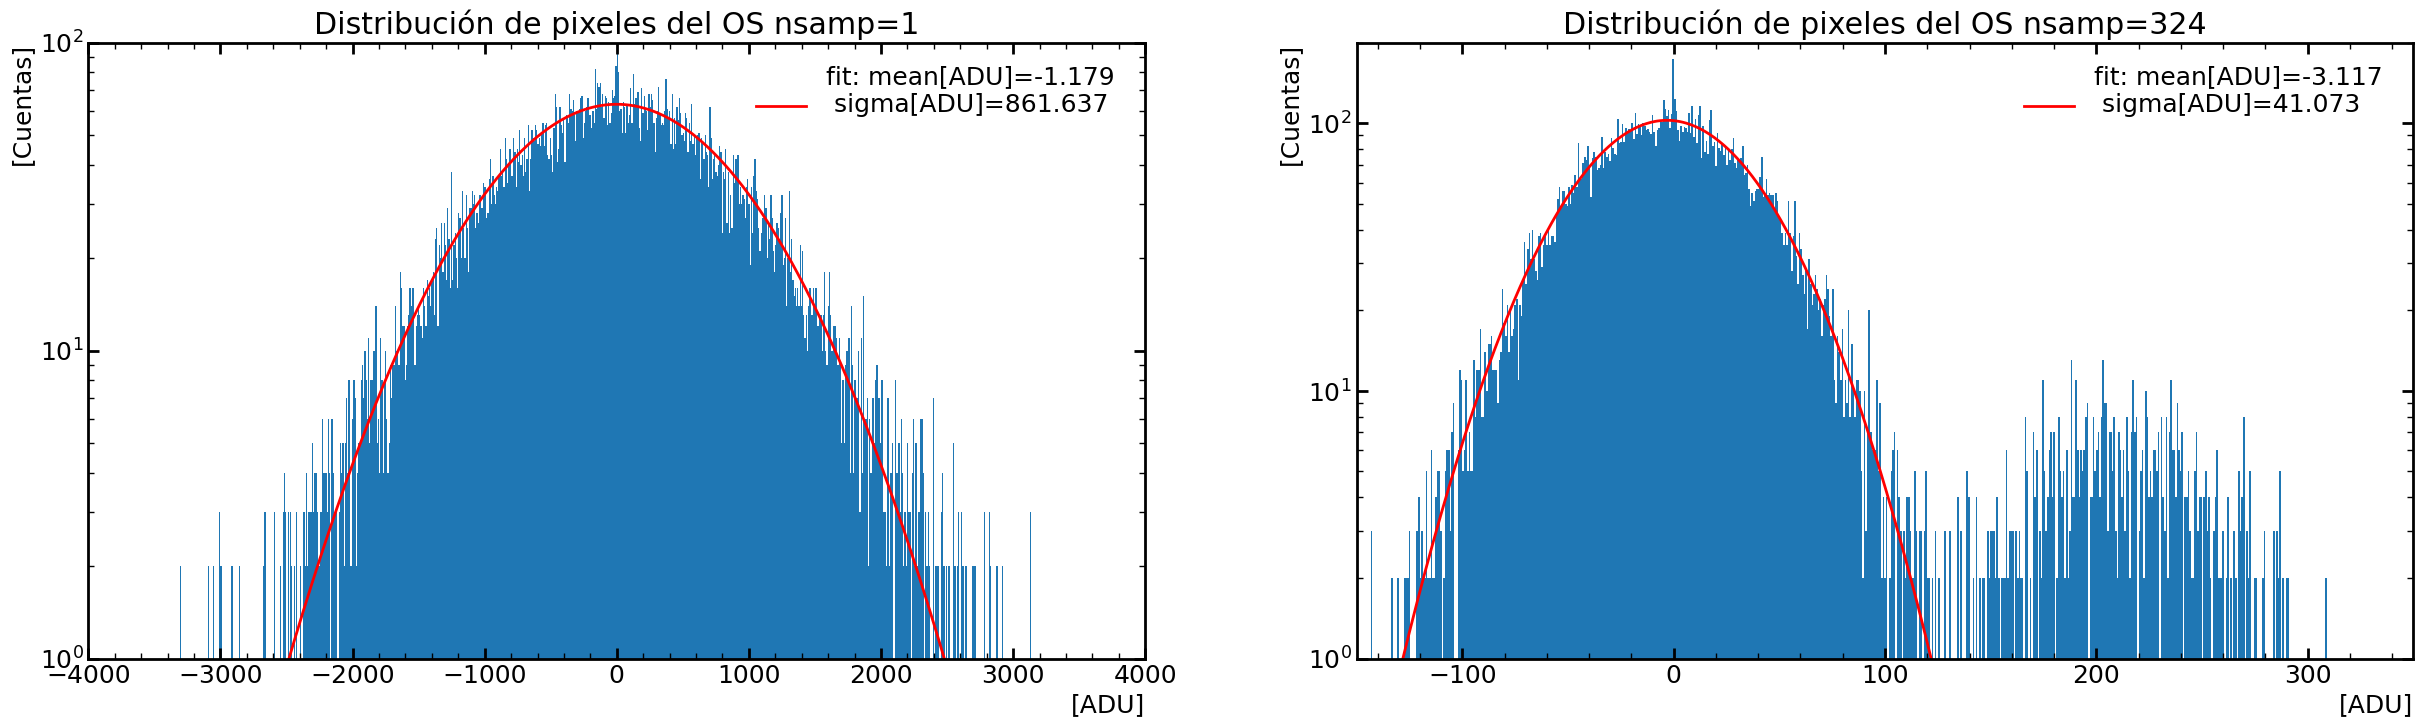

In [31]:
plt.rcParams.update({"font.size":    18.0})
fig, (distribucion_nsamp1, distribucion_nsamp324)=plt.subplots(ncols=2, figsize=(30,8))

counts_Y_nsamp1, bins_X_nsamp1, _ = distribucion_nsamp1.hist(new_image_nsamp1[300:400,550:].flatten(),1000)

bins_nsamp1= (bins_X_nsamp1[1:]+bins_X_nsamp1[:-1])/2
popt_nsamp1,pcov_nsamp1=curve_fit(gauss, bins_nsamp1, counts_Y_nsamp1)
distribucion_nsamp1.plot(bins_nsamp1, gauss(bins_nsamp1, *popt_nsamp1), 'r-', linewidth=2)
distribucion_nsamp1.set(xlim=(-4000,4000), ylim=(1,100), yscale='log', 
                        xlabel='[ADU]', ylabel='[Cuentas]', title='Distribución de pixeles del OS nsamp=1',
                        )
distribucion_nsamp1.legend(['fit: mean[ADU]=%5.3f \n sigma[ADU]=%5.3f \n' % (popt_nsamp1[0],popt_nsamp1[1])], loc='upper right') 




counts_Y_nsamp324, bins_X_nsamp324, _ = distribucion_nsamp324.hist(new_image_nsamp324[500:600,550:].flatten(),1000)
bins_nsamp324= (bins_X_nsamp324[1:]+bins_X_nsamp324[:-1])/2
popt_nsamp324,pcov_nsamp324=curve_fit(gauss, bins_nsamp324, counts_Y_nsamp324)
distribucion_nsamp324.plot(bins_nsamp324, gauss(bins_nsamp324, *popt_nsamp324), 'r-', linewidth=2)
distribucion_nsamp324.set(xlim=(-150,350), ylim=(1,200), yscale='log', 
                          xlabel='[ADU]', ylabel='[Cuentas]', title='Distribución de pixeles del OS nsamp=324'
                          )
bins_nsamp324= (bins_X_nsamp324[1:]+bins_X_nsamp324[:-1])/2
distribucion_nsamp324.legend(['fit: mean[ADU]=%5.3f \n sigma[ADU]=%5.3f \n ' % (popt_nsamp324[0],popt_nsamp324[1])], loc='upper right')

In [32]:
imagen_nsamp324=fits.open(path_nsamp324)
data_Ext=[]
for i in range(0,4):
    data_Ext.append(imagen_nsamp324[i].data)
    

Min_nsamp324=data_nsamp324[0].min()
Max_nsamp324=data_nsamp324[0].max()

NROW_nsamp324=int(imagen_nsamp324[0].header['NROW'])
NCOL_nsamp324=int(imagen_nsamp324[0].header['NCOL'])

new_image=np.zeros(shape=(NROW_nsamp324,NCOL_nsamp324))
for row in range(0,NROW_nsamp324,1):
    for col in range(0,icolOS_low, 1):
        new_image[row][col]=imagen_nsamp324[0].data[row][col]-np.median(imagen_nsamp324[0].data[row,icolOS_low:icolOS_hi])
    for col in range(icolOS_low, NCOL_nsamp324, 1):
        new_image[row][col]=imagen_nsamp324[0].data[row][col]-np.median(imagen_nsamp324[0].data[row,icolOS_low:icolOS_hi])




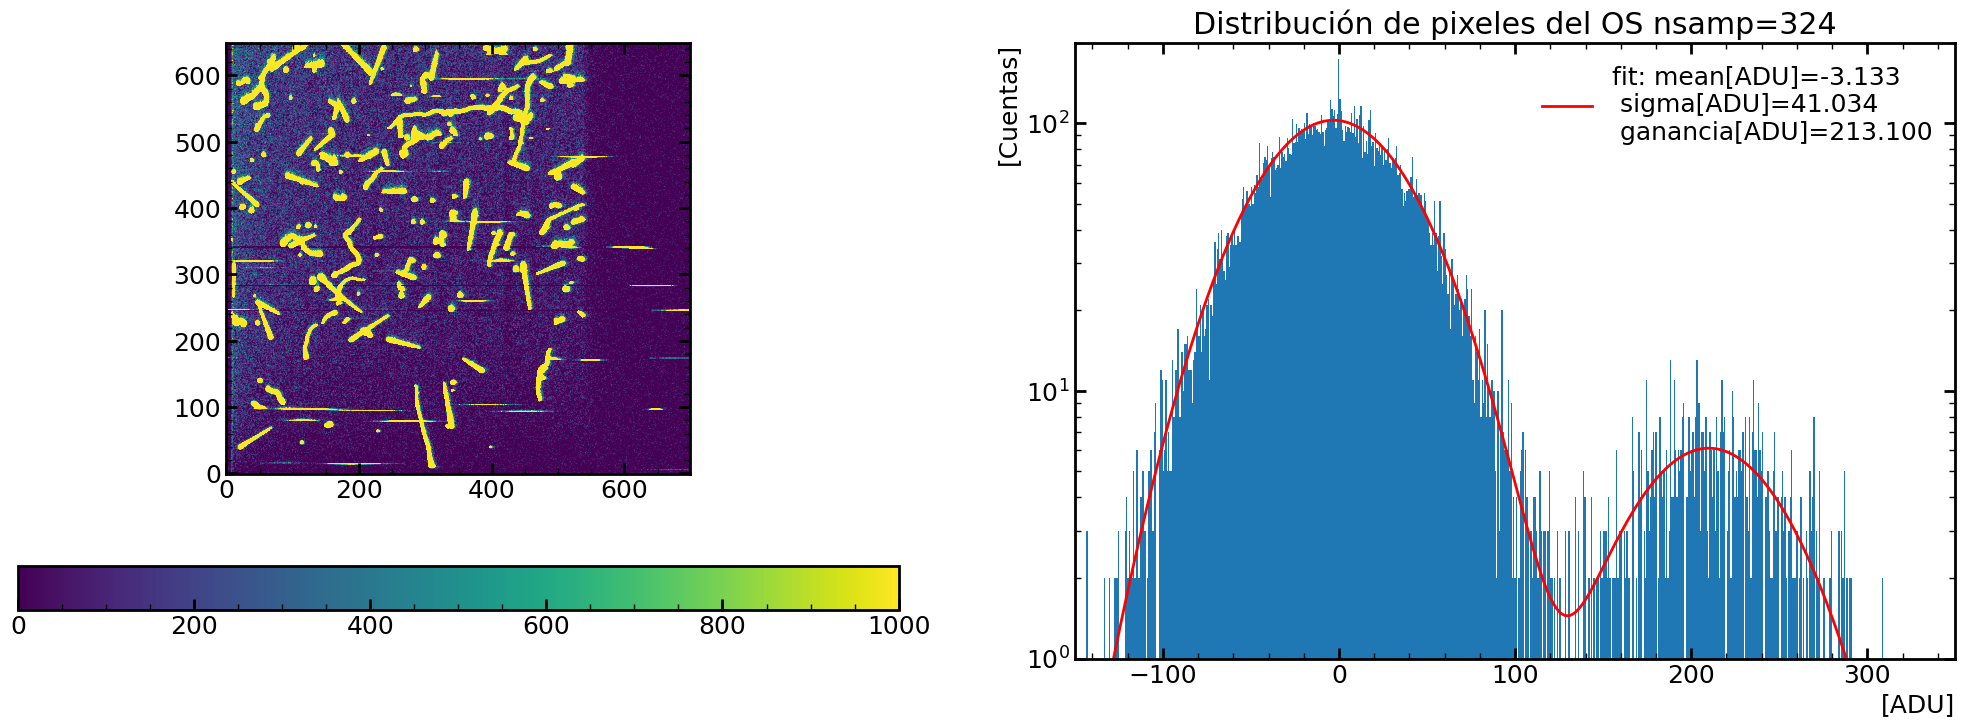

In [33]:


fig, (imagen, distribucion_nsamp324)=plt.subplots(ncols=2, figsize=(25,8))

ok=imagen.imshow(new_image, vmin=0, vmax=1000)

counts_Y_nsamp324, bins_X_nsamp324, _ = distribucion_nsamp324.hist(new_image_nsamp324[500:600,550:].flatten(),1000)
distribucion_nsamp324.set(xlim=(-150,350), ylim=(1,200), yscale='log', xlabel='[ADU]', ylabel='[Cuentas]', title='Distribución de pixeles del OS nsamp=324')

bins_nsamp324= (bins_X_nsamp324[1:]+bins_X_nsamp324[:-1])/2
popt_nsamp324,pcov_nsamp324=curve_fit(gaussian2, bins_nsamp324, counts_Y_nsamp324, p0=(0,40,205,90,10))
distribucion_nsamp324.plot(bins_nsamp324, gaussian2(bins_nsamp324, *popt_nsamp324), 'r-', linewidth=2)


distribucion_nsamp324.legend(['fit: mean[ADU]=%5.3f \n sigma[ADU]=%5.3f \n ganancia[ADU]=%5.3f' % (popt_nsamp324[0],popt_nsamp324[1], popt_nsamp324[2])], loc='upper right')
Ganancia=popt_nsamp324[2]
fig.colorbar(ok, ax=imagen, orientation='horizontal')

In [34]:
imagen_nsamp324=fits.open(path_nsamp324)
data_Ext=[]
for i in range(0,4):
    data_Ext.append(imagen_nsamp324[i].data)
    

Min_nsamp324=data_nsamp324[0].min()
Max_nsamp324=data_nsamp324[0].max()

NROW_nsamp324=int(imagen_nsamp324[0].header['NROW'])
NCOL_nsamp324=int(imagen_nsamp324[0].header['NCOL'])

new_image_cal=np.zeros(shape=(NROW_nsamp324,NCOL_nsamp324))
for row in range(0,NROW_nsamp324,1):
    for col in range(0,icolOS_low, 1):
        new_image_cal[row][col]=(imagen_nsamp324[0].data[row][col]-np.median(imagen_nsamp324[0].data[row,icolOS_low:icolOS_hi]))/Ganancia
    for col in range(icolOS_low, NCOL_nsamp324, 1):
        new_image_cal[row][col]=(imagen_nsamp324[0].data[row][col]-np.median(imagen_nsamp324[0].data[row,icolOS_low:icolOS_hi]))/Ganancia


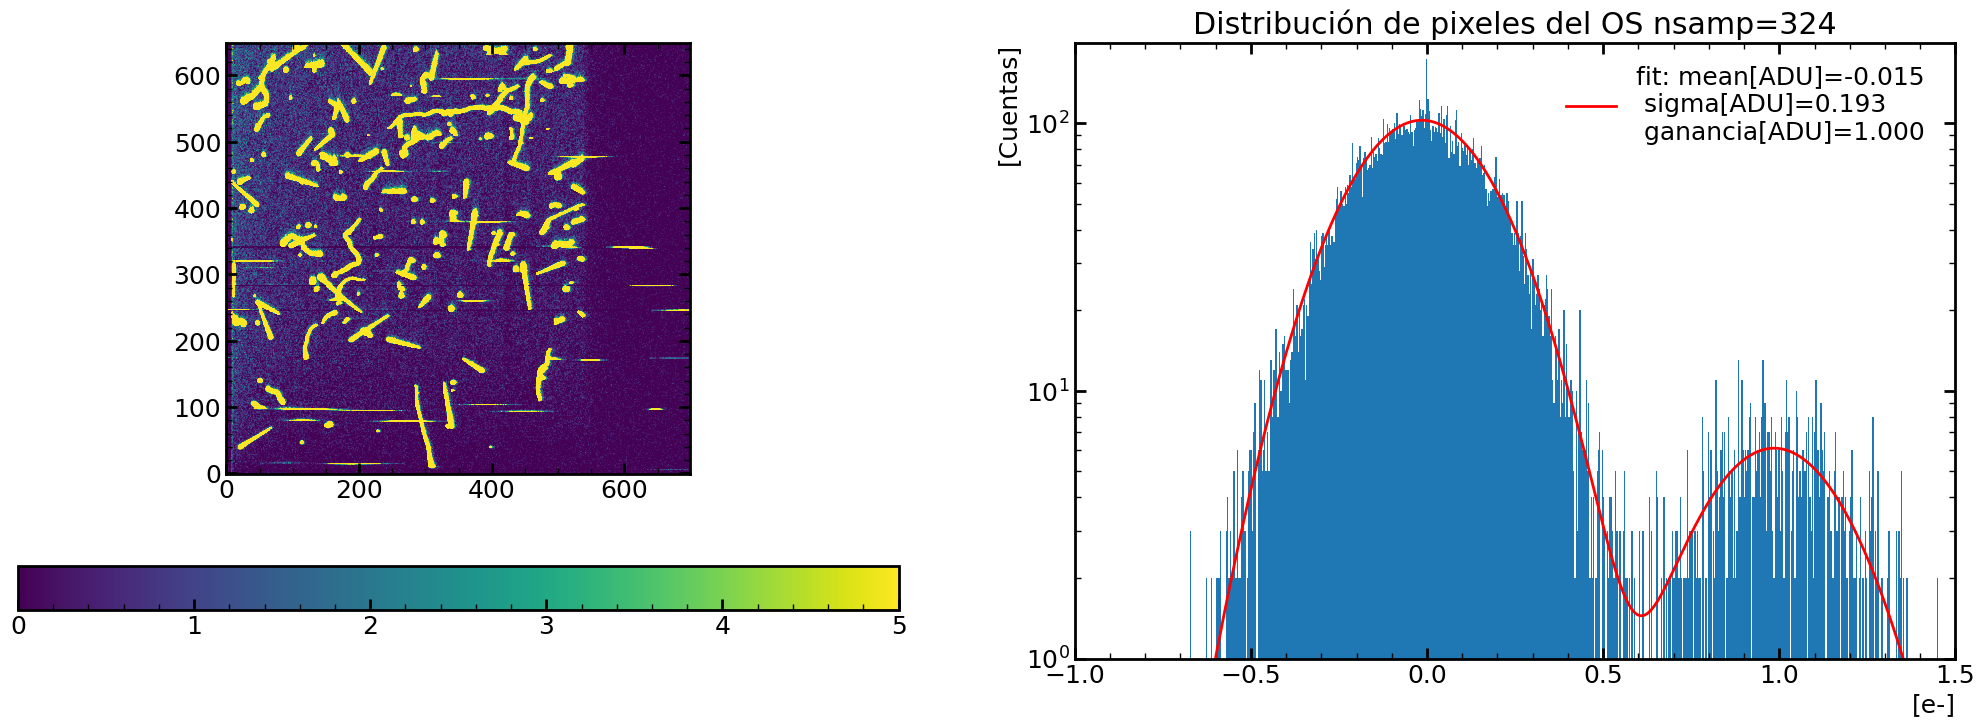

In [35]:
fig, (imagen, distribucion_nsamp324)=plt.subplots(ncols=2, figsize=(25,8))

ok=imagen.imshow(new_image_cal, vmin=0, vmax=5)

counts_Y_nsamp324, bins_X_nsamp324, _ = distribucion_nsamp324.hist(new_image_cal[500:600,550:].flatten(),1000)
distribucion_nsamp324.set(xlim=(-1,1.5), ylim=(1,200), yscale='log', xlabel='[e-]', ylabel='[Cuentas]', title='Distribución de pixeles del OS nsamp=324')

bins_nsamp324= (bins_X_nsamp324[1:]+bins_X_nsamp324[:-1])/2
popt_nsamp324,pcov_nsamp324=curve_fit(gaussian2, bins_nsamp324, counts_Y_nsamp324, p0=[0,.25,1,1e3,1e2])
distribucion_nsamp324.plot(bins_nsamp324, gaussian2(bins_nsamp324, *popt_nsamp324), 'r-', linewidth=2)


distribucion_nsamp324.legend(['fit: mean[ADU]=%5.3f \n sigma[ADU]=%5.3f \n ganancia[ADU]=%5.3f' % (popt_nsamp324[0],popt_nsamp324[1], popt_nsamp324[2])], loc='upper right')

fig.colorbar(ok, ax=imagen, orientation='horizontal')

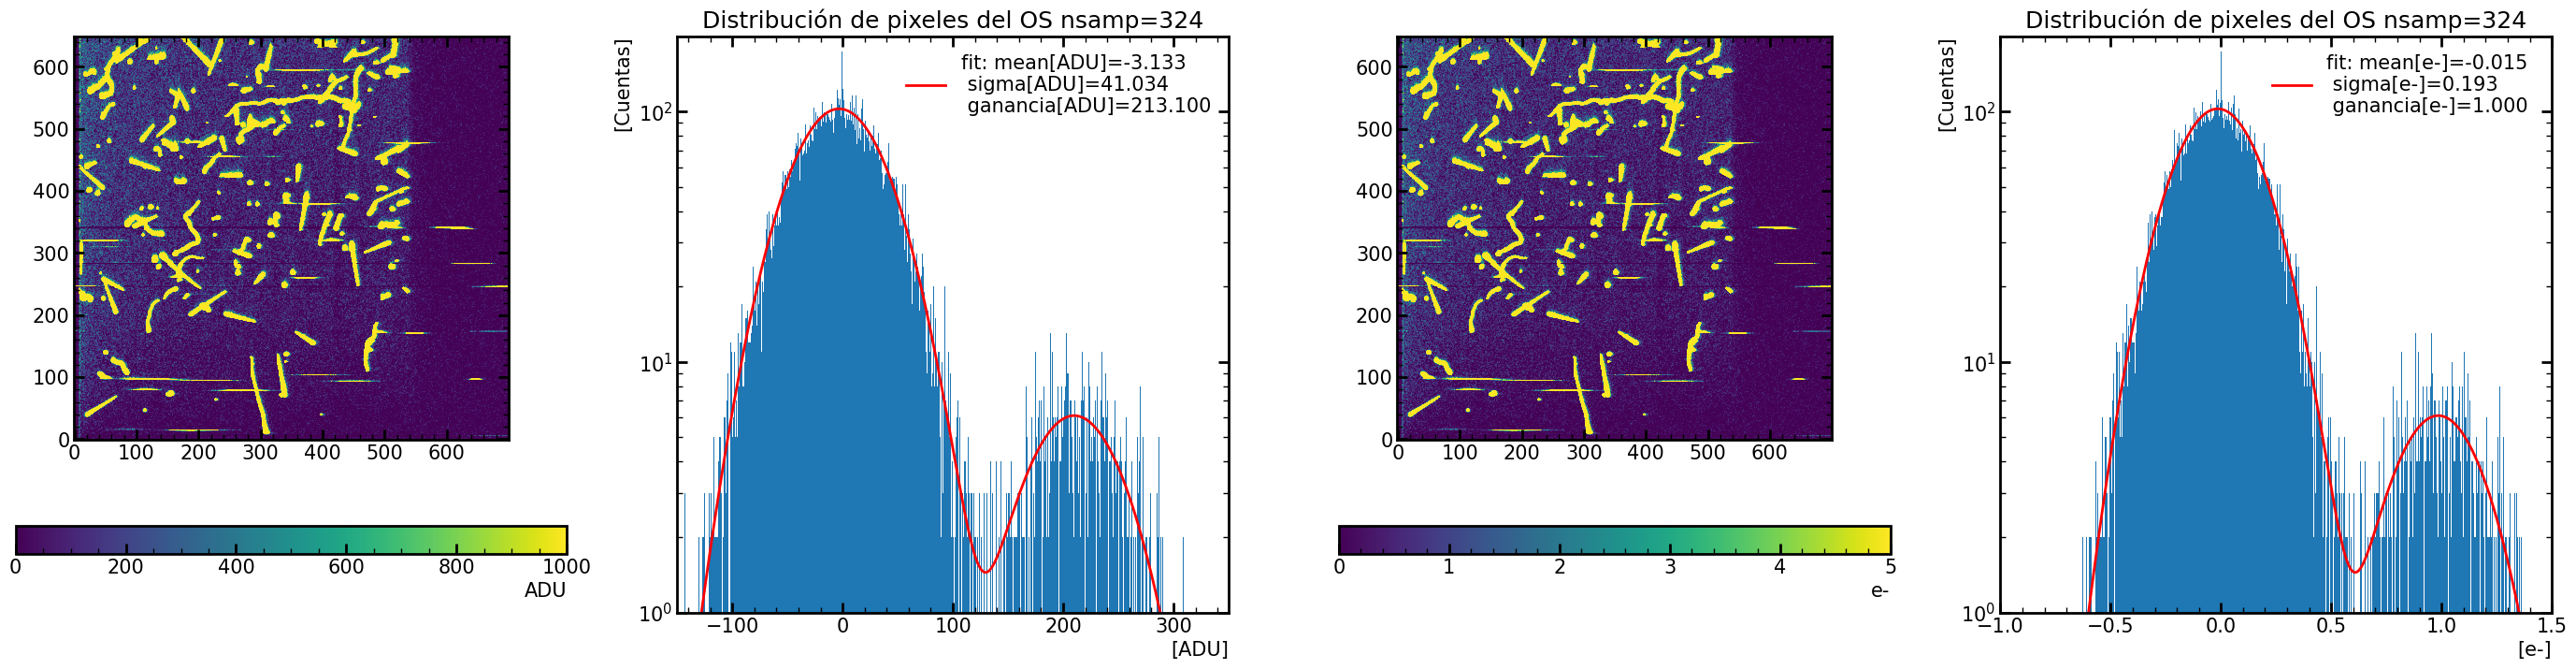

In [47]:
plt.rcParams.update({"font.size":    15.0})
fig, (imagen, dist_adu, imagen_cal,dist_e)=plt.subplots(ncols=4, figsize=(35,8))
ok=imagen.imshow(new_image, vmin=0, vmax=1000)

counts_Y_nsamp324, bins_X_nsamp324, _ = dist_adu.hist(new_image_nsamp324[500:600,550:].flatten(),1000)
dist_adu.set(xlim=(-150,350), ylim=(1,200), yscale='log', xlabel='[ADU]', ylabel='[Cuentas]', title='Distribución de pixeles del OS nsamp=324')

bins_nsamp324= (bins_X_nsamp324[1:]+bins_X_nsamp324[:-1])/2
popt_nsamp324,pcov_nsamp324=curve_fit(gaussian2, bins_nsamp324, counts_Y_nsamp324, p0=(0,40,205,90,10))
dist_adu.plot(bins_nsamp324, gaussian2(bins_nsamp324, *popt_nsamp324), 'r-', linewidth=2)


dist_adu.legend(['fit: mean[ADU]=%5.3f \n sigma[ADU]=%5.3f \n ganancia[ADU]=%5.3f' % (popt_nsamp324[0],popt_nsamp324[1], popt_nsamp324[2])], loc='upper right')
Ganancia=popt_nsamp324[2]

fig.colorbar(ok, ax=imagen, orientation='horizontal', label='ADU')

ok_cal=imagen_cal.imshow(new_image_cal, vmin=0, vmax=5)

counts_Y_cal, bins_X_cal, _ = dist_e.hist(new_image_cal[500:600,550:].flatten(),1000)
dist_e.set(xlim=(-1,1.5), ylim=(1,200), yscale='log', xlabel='[e-]', ylabel='[Cuentas]', title='Distribución de pixeles del OS nsamp=324')

bins_cal= (bins_X_cal[1:]+bins_X_cal[:-1])/2
popt_cal,pcov_cal=curve_fit(gaussian2, bins_cal, counts_Y_cal, p0=[0,.25,1,1e3,1e2])
dist_e.plot(bins_cal, gaussian2(bins_cal, *popt_cal), 'r-', linewidth=2)


dist_e.legend(['fit: mean[e-]=%5.3f \n sigma[e-]=%5.3f \n ganancia[e-]=%5.3f' % (popt_cal[0],popt_cal[1], popt_cal[2])], loc='upper right')



fig.colorbar(ok_cal, ax=imagen_cal, orientation='horizontal', label='e-')
